# Fine-tuning de YOLO para detección de vehículos UAV

Pipeline de instrucción: datos → dataset → baseline COCO → transfer learning (cabeza) → fine-tuning parcial → fine-tuning completo → visualización.

Hardware objetivo: **RTX 4070 Ti** (12 GB). Usamos `AdamW` + precisión mixta (`amp`) vía Ultralytics.


## 1. Imports y datos


In [1]:
import os
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
from torchvision.utils import draw_bounding_boxes
from ultralytics import YOLO

# Dispositivo y hiperparámetros (RTX 4070 Ti ~12 GB VRAM)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32          # YOLO (imgsz=640) cabe cómodo; subir/bajar según VRAM
NUM_WORKERS = 4
NUM_CLASSES = 3         # 3 vehículos (YOLO no reserva clase de fondo)
BASE_MODEL = "yolov8s.pt"  # pesos COCO preentrenados
print(f"Dispositivo: {device}")

# Descarga del dataset de la competencia
path = kagglehub.competition_download(
    "deteccion-de-vehiculos-en-imagenes-uav-en-colombia"
)
data_root = f"{path}/archive"
print("Datos en:", data_root)


/home/daniel/Dropbox/2026-02/Deep Learning/Semana 9/Competencia/.venv_u/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda
Datos en: /home/daniel/.cache/kagglehub/competitions/deteccion-de-vehiculos-en-imagenes-uav-en-colombia/archive


## 2. Dataset

Las anotaciones ya vienen en formato YOLO normalizado (`class_id, x_center, y_center, width, height`).
Para **visualización** convertimos a cajas XYXY en píxeles.
Para **entrenar** con Ultralytics exportamos `.txt` por imagen + `data.yaml` (las clases quedan en `0..2`).


In [2]:
class CarDataset(Dataset):
    """Dataset de detección: imagen + diccionario {boxes, labels} (para visualización)."""

    def __init__(self, annotations_file, img_dir, transform=None):
        df = pd.read_csv(annotations_file)

        # YOLO normalizado → XYXY normalizado (vectorizado)
        x1 = df["x_center"] - df["width"] / 2
        y1 = df["y_center"] - df["height"] / 2
        x2 = df["x_center"] + df["width"] / 2
        y2 = df["y_center"] + df["height"] / 2
        df = df.assign(
            x1=x1, y1=y1, x2=x2, y2=y2,
            label=df["class_id"].astype(int),  # YOLO: clases 0..2 (sin fondo)
        )

        # Una entrada por imagen: (nombre, matriz N×5)
        self.samples = [
            (name, g[["x1", "y1", "x2", "y2", "label"]].to_numpy(np.float32))
            for name, g in df.groupby("image_id", sort=True)
        ]
        self.img_dir = img_dir
        self.transform = transform or T.Compose([
            T.ToImage(),
            T.ToDtype(torch.float32, scale=True),
        ])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_name, arr = self.samples[idx]
        if not str(img_name).lower().endswith((".jpg", ".jpeg", ".png")):
            img_name = f"{img_name}.jpg"

        image = Image.open(os.path.join(self.img_dir, img_name)).convert("RGB")
        w, h = image.size

        boxes = torch.as_tensor(arr[:, :4], dtype=torch.float32)
        boxes[:, [0, 2]] *= w
        boxes[:, [1, 3]] *= h
        labels = torch.as_tensor(arr[:, 4], dtype=torch.int64)

        boxes = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=(h, w))
        image, boxes = self.transform(image, boxes)

        return image, {"boxes": boxes, "labels": labels}


def collate_fn(batch):
    """Apila imágenes; deja targets como lista (N variable de cajas)."""
    images, targets = zip(*batch)
    return torch.stack(images), list(targets)


def export_yolo_split(annotations_file, img_dir, out_root, split):
    """CSV → labels YOLO (.txt) + symlinks de imágenes para Ultralytics."""
    df = pd.read_csv(annotations_file)
    img_out = Path(out_root) / "images" / split
    lbl_out = Path(out_root) / "labels" / split
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)
    src_imgs = Path(img_dir).resolve()

    n_imgs = 0
    for name, g in df.groupby("image_id", sort=True):
        n_imgs += 1
        fname = str(name) if str(name).lower().endswith((".jpg", ".jpeg", ".png")) else f"{name}.jpg"
        stem = Path(fname).stem
        src = src_imgs / fname
        dst = img_out / fname
        if not dst.exists():
            dst.symlink_to(src)

        lines = [
            f"{int(r.class_id)} {r.x_center:.6f} {r.y_center:.6f} {r.width:.6f} {r.height:.6f}"
            for r in g.itertuples()
        ]
        (lbl_out / f"{stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
    return n_imgs


yolo_root = Path("yolo_uav_dataset").resolve()
n_train = export_yolo_split(
    f"{data_root}/training/training_labels.csv",
    f"{data_root}/training/images/",
    yolo_root,
    "train",
)
n_val = export_yolo_split(
    f"{data_root}/validation/validation_labels.csv",
    f"{data_root}/validation/images/",
    yolo_root,
    "val",
)

data_yaml = yolo_root / "data.yaml"
data_yaml.write_text(yaml.safe_dump({
    "path": str(yolo_root),
    "train": "images/train",
    "val": "images/val",
    "nc": NUM_CLASSES,
    "names": {0: "0", 1: "1", 2: "2"},
}, sort_keys=False))
print(f"YOLO dataset: {n_train} train / {n_val} val → {data_yaml}")

train_ds = CarDataset(
    annotations_file=f"{data_root}/training/training_labels.csv",
    img_dir=f"{data_root}/training/images/",
)
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)
print(f"{len(train_ds)} imágenes de entrenamiento")


YOLO dataset: 5680 train / 1004 val → /home/daniel/Dropbox/2026-02/Deep Learning/Semana 9/Competencia/yolo_uav_dataset/data.yaml
5680 imágenes de entrenamiento


## 3. Vista rápida de un lote


Lote: torch.Size([32, 3, 1080, 1920]) | cajas/img: [79, 80, 60, 86, 53, 47, 56, 38, 75, 75, 76, 64, 83, 57, 88, 66, 34, 74, 85, 81, 54, 55, 47, 70, 55, 47, 80, 81, 39, 66, 95, 74]


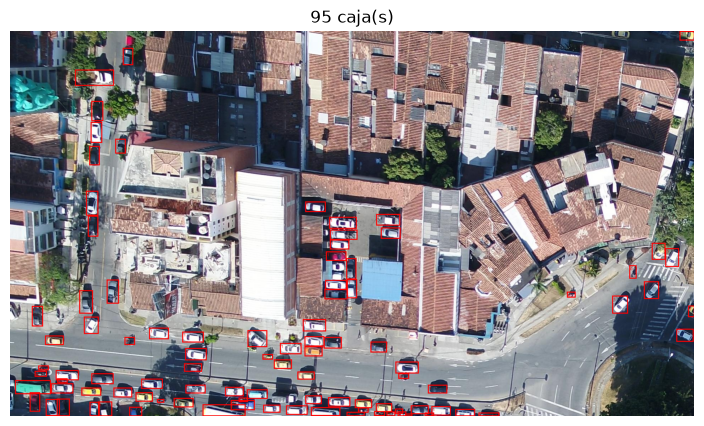

In [3]:
images, targets = next(iter(train_loader))
print("Lote:", images.shape, "| cajas/img:", [t["boxes"].shape[0] for t in targets])

# Imagen con más detecciones del lote
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
vis = draw_bounding_boxes(
    (images[idx] * 255).to(torch.uint8),
    boxes=targets[idx]["boxes"],
    labels=[str(int(x)) for x in targets[idx]["labels"]],
    colors="red",
    width=3,
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(vis.permute(1, 2, 0).numpy())
ax.set_title(f"{len(targets[idx]['boxes'])} caja(s)")
ax.axis("off")
plt.show()


## 4. Baseline: inferencia con pesos COCO (sin fine-tuning)

Útil para ver qué detecta el modelo preentrenado antes de adaptarlo.


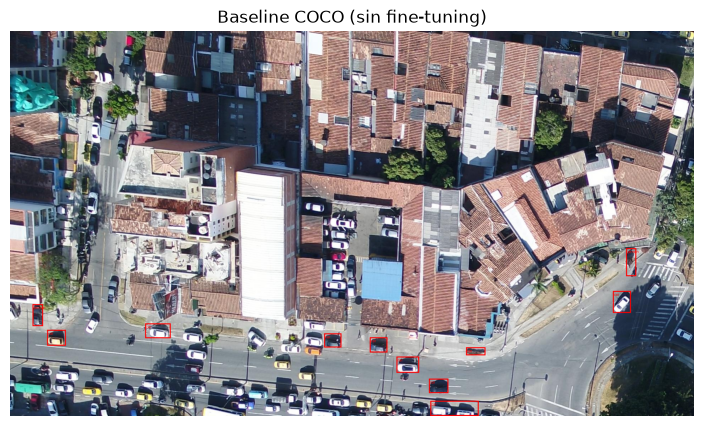

In [4]:
# Imagen del lote (tensor → PIL) para YOLO
img_u8 = (images[idx] * 255).to(torch.uint8)
pil_img = T.ToPILImage()(img_u8)

baseline = YOLO(BASE_MODEL)
pred = baseline.predict(pil_img, conf=0.25, verbose=False)[0]

names = pred.names
boxes = pred.boxes.xyxy.cpu() if pred.boxes is not None else torch.zeros((0, 4))
cls_ids = pred.boxes.cls.int().cpu().tolist() if pred.boxes is not None else []
labels = [names[i] for i in cls_ids]

box_img = draw_bounding_boxes(
    img_u8,
    boxes=boxes,
    labels=labels,
    colors="red",
    width=3,
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(box_img.permute(1, 2, 0).numpy())
ax.set_title("Baseline COCO (sin fine-tuning)")
ax.axis("off")
plt.show()

del baseline  # liberar VRAM antes del entrenamiento
torch.cuda.empty_cache()


## 5. Transfer learning: solo la cabeza de detección

Congelamos backbone + neck (`freeze=22`) y entrenamos la cabeza Detect para nuestras 3 clases.
Ultralytics usa **AdamW** + **AMP** por defecto.


In [5]:
# Modelo preentrenado COCO; Ultralytics adapta la cabeza a nc=3 vía data.yaml
model = YOLO(BASE_MODEL)

EPOCHS_HEAD = 5
results_head = model.train(
    data=str(data_yaml),
    epochs=EPOCHS_HEAD,
    imgsz=640,
    batch=BATCH_SIZE,
    workers=NUM_WORKERS,
    device=0 if device.type == "cuda" else "cpu",
    optimizer="AdamW",
    lr0=1e-3,
    weight_decay=1e-4,
    freeze=22,          # solo la cabeza (módulo Detect)
    amp=True,
    pretrained=True,
    project="runs_yolo_uav",
    name="head",
    exist_ok=True,
    verbose=True,
)

# Reanudar desde el mejor checkpoint de esta etapa
model = YOLO(str(Path(results_head.save_dir) / "weights" / "best.pt"))
print("Checkpoint cabeza:", Path(results_head.save_dir) / "weights" / "best.pt")


Ultralytics 8.4.173 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 15935MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/daniel/Dropbox/2026-02/Deep Learning/Semana 9/Competencia/yolo_uav_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=22, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, 

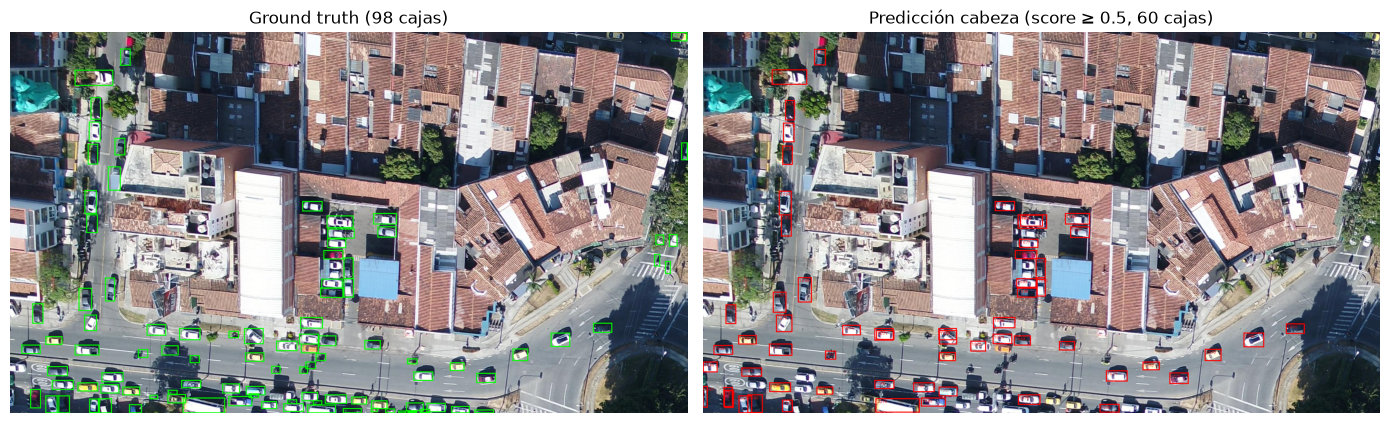

In [6]:
CLASS_NAMES = {0: "0", 1: "1", 2: "2"}
SCORE_THR = 0.5

images, targets = next(iter(train_loader))
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
img = images[idx]
img_u8 = (img * 255).to(torch.uint8)
pil_img = T.ToPILImage()(img_u8)

pred = model.predict(pil_img, conf=SCORE_THR, verbose=False)[0]
pred_boxes = pred.boxes.xyxy.cpu() if pred.boxes is not None else torch.zeros((0, 4))
pred_labels = [
    f"{CLASS_NAMES.get(int(c), str(int(c)))} {s:.2f}"
    for c, s in zip(pred.boxes.cls.int().cpu().tolist(), pred.boxes.conf.cpu().tolist())
] if pred.boxes is not None else []
gt_labels = [CLASS_NAMES.get(int(l), str(int(l))) for l in targets[idx]["labels"]]

gt_vis = draw_bounding_boxes(img_u8, targets[idx]["boxes"], labels=gt_labels, colors="lime", width=3)
pred_vis = draw_bounding_boxes(img_u8, pred_boxes, labels=pred_labels, colors="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gt_vis.permute(1, 2, 0).numpy())
axes[0].set_title(f"Ground truth ({len(targets[idx]['boxes'])} cajas)")
axes[0].axis("off")
axes[1].imshow(pred_vis.permute(1, 2, 0).numpy())
axes[1].set_title(f"Predicción cabeza (score ≥ {SCORE_THR}, {len(pred_boxes)} cajas)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 6. Fine-tuning parcial: neck + cabeza (`freeze=10`)

Descongelamos el neck (backbone sigue congelado) y bajamos el learning rate para no destruir features preentrenadas.


In [7]:
EPOCHS_FT = 5
results_ft = model.train(
    data=str(data_yaml),
    epochs=EPOCHS_FT,
    imgsz=640,
    batch=max(4, BATCH_SIZE // 2),  # un poco más de VRAM al descongelar
    workers=NUM_WORKERS,
    device=0 if device.type == "cuda" else "cpu",
    optimizer="AdamW",
    lr0=1e-4,           # LR más bajo al actualizar más capas
    weight_decay=1e-4,
    freeze=10,          # backbone congelado; neck + cabeza entrenables
    amp=True,
    project="runs_yolo_uav",
    name="finetune",
    exist_ok=True,
    verbose=True,
)

model = YOLO(str(Path(results_ft.save_dir) / "weights" / "best.pt"))
print("Checkpoint fine-tune:", Path(results_ft.save_dir) / "weights" / "best.pt")


Ultralytics 8.4.173 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 15935MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/daniel/Dropbox/2026-02/Deep Learning/Semana 9/Competencia/yolo_uav_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/daniel/Dropbox/2026-02/Deep Learn


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/5      1.92G      1.816     0.8598     0.8681        848        640: 100% ━━━━━━━━━━━━ 355/355 24.4it/s 14.5s0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 11.9it/s 2.7s0.1s
                   all       1004      67914      0.687      0.505      0.558      0.263

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/5      1.94G      1.715     0.8064      0.854        858        640: 100% ━━━━━━━━━━━━ 355/355 25.4it/s 14.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 15.8it/s 2.0s0.1s
                   all       1004      67914      0.707      0.539      0.581      0.284

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/5      1.94G      1.667     0.7805     0.8458        862       

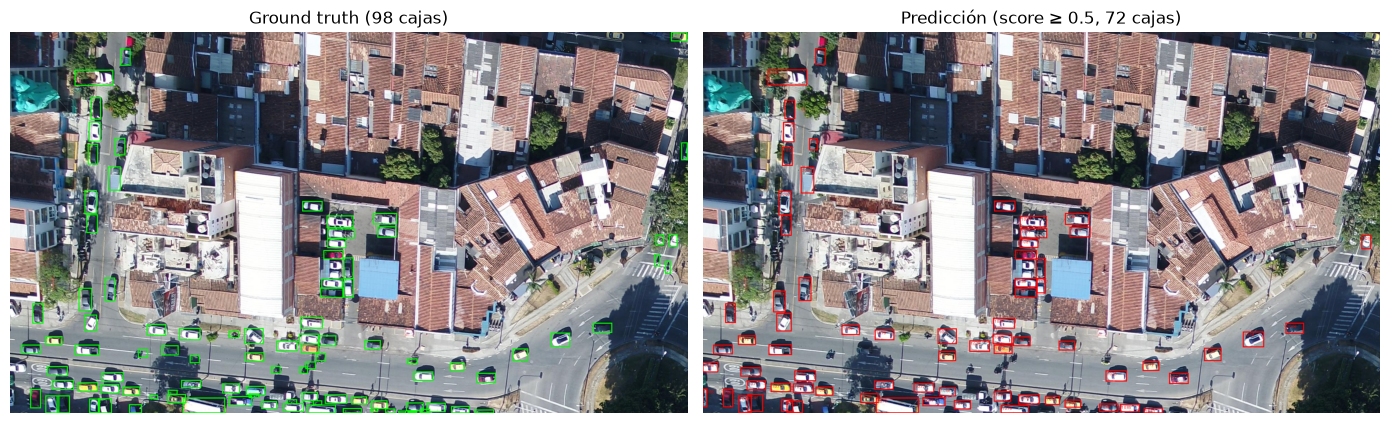

In [8]:
CLASS_NAMES = {0: "0", 1: "1", 2: "2"}
SCORE_THR = 0.5

images, targets = next(iter(train_loader))
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
img = images[idx]
img_u8 = (img * 255).to(torch.uint8)
pil_img = T.ToPILImage()(img_u8)

pred = model.predict(pil_img, conf=SCORE_THR, verbose=False)[0]
pred_boxes = pred.boxes.xyxy.cpu() if pred.boxes is not None else torch.zeros((0, 4))
pred_labels = [
    f"{CLASS_NAMES.get(int(c), str(int(c)))} {s:.2f}"
    for c, s in zip(pred.boxes.cls.int().cpu().tolist(), pred.boxes.conf.cpu().tolist())
] if pred.boxes is not None else []
gt_labels = [CLASS_NAMES.get(int(l), str(int(l))) for l in targets[idx]["labels"]]

gt_vis = draw_bounding_boxes(img_u8, targets[idx]["boxes"], labels=gt_labels, colors="lime", width=3)
pred_vis = draw_bounding_boxes(img_u8, pred_boxes, labels=pred_labels, colors="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gt_vis.permute(1, 2, 0).numpy())
axes[0].set_title(f"Ground truth ({len(targets[idx]['boxes'])} cajas)")
axes[0].axis("off")
axes[1].imshow(pred_vis.permute(1, 2, 0).numpy())
axes[1].set_title(f"Predicción (score ≥ {SCORE_THR}, {len(pred_boxes)} cajas)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 7. Fine-tuning completo: todo el modelo (`freeze=0`)

Descongelamos **todas** las capas (backbone + neck + cabeza) y usamos un learning rate aún más bajo para adaptar features tempranas sin olvidar COCO.

In [12]:
EPOCHS_FULL = 20
results_full = model.train(
    data=str(data_yaml),
    epochs=EPOCHS_FULL,
    imgsz=640,
    batch=max(2, BATCH_SIZE // 5),  # más VRAM con backbone entrenable
    workers=NUM_WORKERS,
    device=0 if device.type == "cuda" else "cpu",
    optimizer="AdamW",
    lr0=1e-7,           # LR aún más bajo: todo el modelo se actualiza
    weight_decay=1e-4,
    freeze=0,           # sin capas congeladas
    amp=True,
    project="runs_yolo_uav",
    name="full",
    exist_ok=True,
    verbose=True,
)

model = YOLO(str(Path(results_full.save_dir) / "weights" / "best.pt"))
print("Checkpoint full:", Path(results_full.save_dir) / "weights" / "best.pt")

Ultralytics 8.4.173 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4070 Ti SUPER, 15935MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/daniel/Dropbox/2026-02/Deep Learning/Semana 9/Competencia/yolo_uav_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=1e-07, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/daniel/Dropbox/2026-02/Deep Learnin

[W1005 13:53:04.846287151 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 4063232, total: 16708927488).


       1/20      3.37G      1.631     0.7479     0.8194        357        640: 100% ━━━━━━━━━━━━ 947/947 36.4it/s 26.0s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 32.9it/s 2.6s0.0s
                   all       1004      67914      0.745      0.612      0.641      0.307

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/20      3.37G      1.597     0.7307     0.8149        388        640: 100% ━━━━━━━━━━━━ 947/947 37.1it/s 25.5s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 39.3it/s 2.1s0.1s
                   all       1004      67914      0.766      0.622       0.65      0.324

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      3.37G      1.572      0.722     0.8151        643        640: 100% ━━━━━━━━━━━━ 947/947 37.2it/s 25.4s0.1ss
                 Class   

KeyboardInterrupt: 

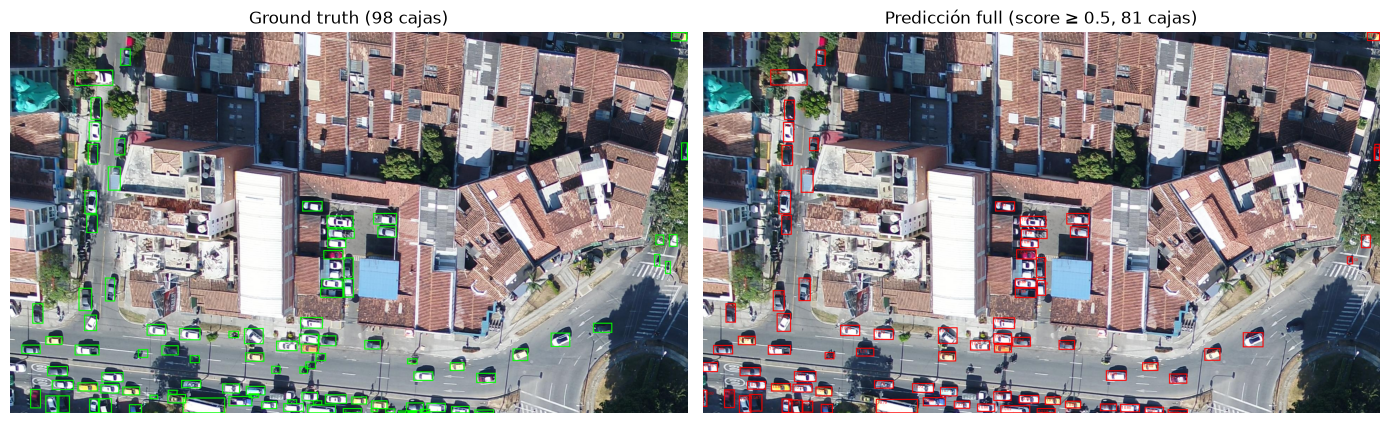

In [13]:
CLASS_NAMES = {0: "0", 1: "1", 2: "2"}
SCORE_THR = 0.5

images, targets = next(iter(train_loader))
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
img = images[idx]
img_u8 = (img * 255).to(torch.uint8)
pil_img = T.ToPILImage()(img_u8)

pred = model.predict(pil_img, conf=SCORE_THR, verbose=False)[0]
pred_boxes = pred.boxes.xyxy.cpu() if pred.boxes is not None else torch.zeros((0, 4))
pred_labels = [
    f"{CLASS_NAMES.get(int(c), str(int(c)))} {s:.2f}"
    for c, s in zip(pred.boxes.cls.int().cpu().tolist(), pred.boxes.conf.cpu().tolist())
] if pred.boxes is not None else []
gt_labels = [CLASS_NAMES.get(int(l), str(int(l))) for l in targets[idx]["labels"]]

gt_vis = draw_bounding_boxes(img_u8, targets[idx]["boxes"], labels=gt_labels, colors="lime", width=3)
pred_vis = draw_bounding_boxes(img_u8, pred_boxes, labels=pred_labels, colors="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gt_vis.permute(1, 2, 0).numpy())
axes[0].set_title(f"Ground truth ({len(targets[idx]['boxes'])} cajas)")
axes[0].axis("off")
axes[1].imshow(pred_vis.permute(1, 2, 0).numpy())
axes[1].set_title(f"Predicción full (score ≥ {SCORE_THR}, {len(pred_boxes)} cajas)")
axes[1].axis("off")
plt.tight_layout()
plt.show()